# Baseline: default Spraypoint

What does the network look like with no bypass? This sets the numbers the bypass has to beat.

Reads the baseline runs of the sweep set by `SWEEP` in `common.py`, so it shows whatever runs have finished. Rerun it as more arrive.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common

common.setup_plots()
pd.options.display.float_format = "{:,.2f}".format

runs = common.load_runs(common.BASELINE_EXPERIMENT)
flows = common.load_flows(runs)
links = common.load_links(runs)
print(f"Reading {common.MACHINE}/{common.BATCH}")
print(f"{len(runs)} finished runs, {', '.join(common.SETTING_LABELS[s].lower() for s in common.SETTINGS)} {sorted({r.setting for r in runs})}, seeds {sorted({r.seed for r in runs})}")

Reading remote/2026-11-07_120750_5770a94
9 finished runs, offered load [0.1, 0.3, 0.5], seeds [561, 562, 563]


## Are the runs healthy?

`unfinished`, `ttl_drops` and `no_route_drops` should all be 0. Queue drops are normal under load.

In [2]:
health = common.runs_table(runs)
display(health)

problems = health[(health["unfinished"] > 0) | (health["ttl_drops"] > 0) | (health["no_route_drops"] > 0)]
print("All runs healthy" if problems.empty else f"Check these runs:\n{problems}")

,run,bypass,load,hosts,share,seed,flows,unfinished,ttl_drops,no_route_drops,queue_drops,wall_minutes,peak_memory_mb,commit
0,load-0.1_seed-561,none,0.10,4,0.08,561,47088,0,0,0,170,7.50,828.40,bdd4cb8
1,load-0.1_seed-562,none,0.10,4,0.08,562,46997,0,0,0,142,11.70,825.50,bdd4cb8
2,load-0.1_seed-563,none,0.10,4,0.08,563,47024,0,0,0,188,7.40,813.50,bdd4cb8
3,load-0.3_seed-561,none,0.30,4,0.08,561,140825,0,0,0,16332,29.10,"2,360.90",bdd4cb8
4,load-0.3_seed-562,none,0.30,4,0.08,562,140876,0,0,0,16411,31.60,"2,373.60",bdd4cb8
5,load-0.3_seed-563,none,0.30,4,0.08,563,140820,0,0,0,15742,29.10,"2,401.30",bdd4cb8
6,load-0.5_seed-561,none,0.50,4,0.08,561,234933,0,0,0,122427,56.90,"4,121.40",bdd4cb8
7,load-0.5_seed-562,none,0.50,4,0.08,562,234811,0,0,0,126087,61.60,"4,121.10",bdd4cb8
8,load-0.5_seed-563,none,0.50,4,0.08,563,235206,0,0,0,123562,56.20,"4,137.00",bdd4cb8


All runs healthy


## What traffic is it?

Small flows are most of the flows but few of the bytes, so a bypass that moves only small flows moves little traffic. The adjacent class is the share of router pairs that are neighbors, about *d*/(*n* − 1).

In [3]:
display(common.traffic_mix(flows, common.SETTINGS).unstack("class"))

flows                            bytes                           
class large small_adjacent small_other large small_adjacent small_other
load                                                                   
0.10   0.10           0.06        0.84  0.92           0.01        0.08
0.30   0.10           0.06        0.84  0.92           0.01        0.08
0.50   0.10           0.06        0.84  0.92           0.01        0.08

## Flow completion times

Pooled across seeds, leaving out flows that start in the first and last 10% of a run, when the network sees less load. `beyond_p99` is how many flows the p99 rests on: below about 100, treat it as noisy, and the same goes for p99.9 at 10 times that flow count.

In [4]:
display(common.fct_table(flows, ["class", *common.SETTINGS]))

flows  unfinished    p50      p99     p99.9  beyond_p99
class          load                                                          
large          0.10   11402           0 180.35   283.11    356.96         114
               0.30   33922           0 258.01   569.81 10,094.67         339
               0.50   56536           0 413.62 1,439.63 10,159.31         565
small_adjacent 0.10    6367           0   9.99    16.83     24.90          63
               0.30   18947           0  11.63    31.56  1,054.41         189
               0.50   31558           0  16.89 1,043.07 10,010.49         315
small_other    0.10   94962           0  10.52    17.58     25.68         949
               0.30  284979           0  12.26    33.36  1,063.13        2849
               0.50  475840           0  18.06 1,048.17 10,010.49        4758

### The tail of the distribution

Each line shows the share of flows slower than a given time, so the far right of each panel is the tail. A jump near 1,000 µs or 10,000 µs is usually a retransmission timeout or a lost SYN, not queueing.

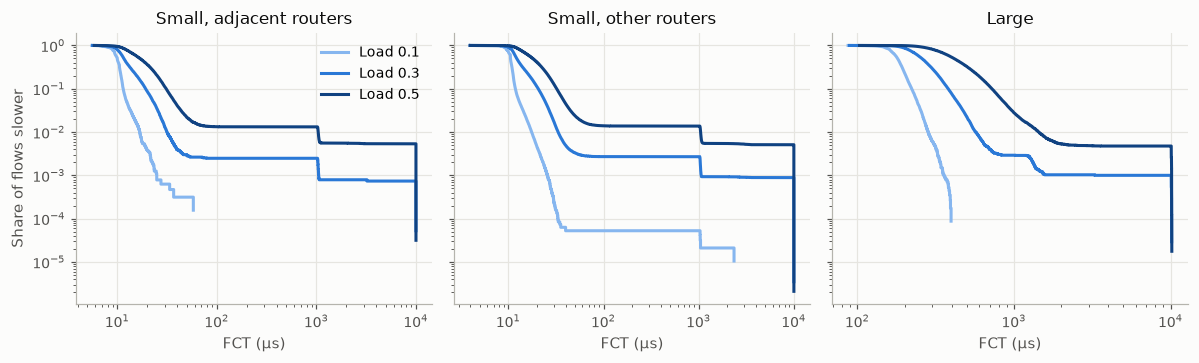

In [5]:
colors = common.setting_colors(flows[common.SETTING])
for title, rows in common.panels(flows):
    figure, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for axis, flow_class in zip(axes, common.CLASSES):
        for value, group in rows[rows["class"] == flow_class].groupby(common.SETTING):
            x, y = common.tail_curve(group["fct_us"].to_numpy())
            axis.step(x, y, color=colors[value], label=common.setting_name(value), where="post")
        axis.set(title=common.CLASS_NAMES[flow_class], xscale="log", yscale="log", xlabel="FCT (µs)")
    axes[0].set_ylabel("Share of flows slower")
    axes[0].legend()
    if title:
        figure.suptitle(title)
    figure.tight_layout()

### Where the tail comes from

A small flow that loses nothing finishes within a few hundred microseconds, so one that takes 1 ms or more waited for a timeout: the 1 ms minimum RTO for lost data, or the 10 ms handshake timeout for a lost SYN or SYN-ACK. A class's p99 jumps to about 1,000 µs once more than 1% of its flows wait for a timeout, and to about 10,000 µs once more than 1% wait for a handshake timeout. So the tail here counts losses more than it measures queueing.

`clean_p50`, `clean_p99` and `clean_max` describe the flows with no timeout, which is the queueing alone. The grey line in the plot is 1%, where the p99 jumps.

In [6]:
display(common.timeout_table(flows, ["class", *common.SETTINGS]))

flows  data_timeout_pct  handshake_timeout_pct  \
class          load                                                    
small_adjacent 0.10    6367              0.00                   0.02   
               0.30   18947              0.17                   0.07   
               0.50   31558              0.78                   0.54   
small_other    0.10   94962              0.00                   0.00   
               0.30  284979              0.18                   0.09   
               0.50  475840              0.87                   0.51   

                     any_timeout_pct  clean_p50  clean_p99  clean_max  
class          load                                                    
small_adjacent 0.10             0.02       9.99      16.77      58.04  
               0.30             0.25      11.63      30.30      78.83  
               0.50             1.32      16.77      49.00     150.69  
small_other    0.10             0.01      10.52      17.56      39.97  
               0.30             0.27      12.25      31.89     100.34  
               0.50             1.38      17.92      50.35     191.27

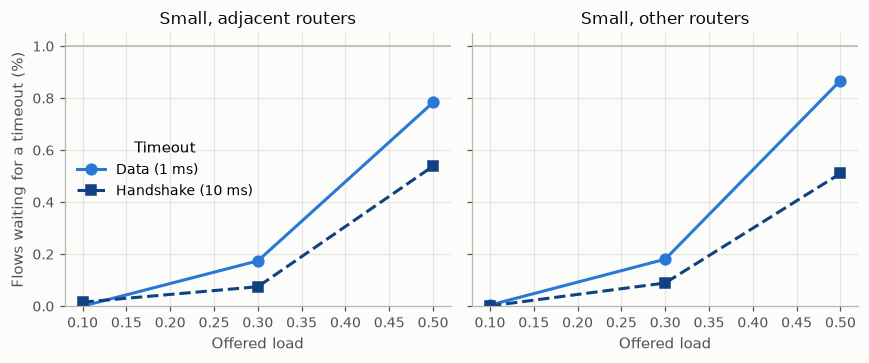

In [7]:
timeouts = common.timeout_table(flows, ["class", *common.SETTINGS, "seed"]).reset_index()
for title, rows in common.panels(timeouts):
    figure, axes = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
    for axis, flow_class in zip(axes, common.SMALL_CLASSES):
        data = rows[rows["class"] == flow_class].groupby(common.SETTING)[["data_timeout_pct", "handshake_timeout_pct"]].mean()
        axis.plot(data.index, data["data_timeout_pct"], color="#2a78d6", marker="o", label="Data (1 ms)")
        axis.plot(data.index, data["handshake_timeout_pct"], color="#104281", marker="s", linestyle="--", label="Handshake (10 ms)")
        axis.axhline(1, color="#b5b4ad", linewidth=1)
        axis.set(title=common.CLASS_NAMES[flow_class])
        common.label_setting_axis(axis)
    axes[0].set_ylim(bottom=0)
    axes[0].set_ylabel("Flows waiting for a timeout (%)")
    axes[0].legend(title="Timeout")
    if title:
        figure.suptitle(title)
    figure.tight_layout()

## Large-flow throughput

Each large flow's goodput is its bytes over its FCT, against 100 Gbps links. `p1` is the slowest 1% of flows, which a hotspot would hurt first.

In [8]:
display(common.goodput_table(flows, common.SETTINGS))

,flows,mean,p50,p10,p1
load,,,,,
0.10,11402,44.77,44.36,36.01,28.26
0.30,33922,31.20,31.01,21.05,14.04
0.50,56536,19.99,19.34,11.07,5.56


## Paths

Share of delivered packets, including ACKs, at each number of fabric hops. Spraying means adjacent routers still mostly use long paths: this is the gap the bypass targets.

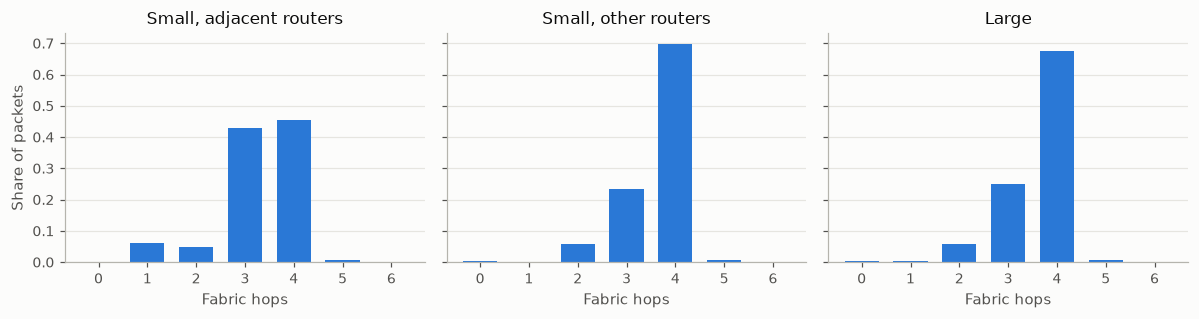

In [9]:
paths = common.path_table(runs).groupby(["class", "hops"])["fraction"].mean().reset_index()
figure, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for axis, flow_class in zip(axes, common.CLASSES):
    data = paths[(paths["class"] == flow_class) & (paths["hops"] <= 6)]
    axis.bar(data["hops"], data["fraction"], color=common.MODE_COLORS["none"], width=0.7)
    axis.set(title=common.CLASS_NAMES[flow_class], xlabel="Fabric hops")
    axis.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of packets")
figure.tight_layout()

## Links

How evenly does traffic spread? `hotspot_ratio` is the busiest link's utilization over the mean. This is the baseline for H2's question of whether the bypass creates hotspots.

In [10]:
display(common.link_table(links, common.SETTINGS))

,mean_utilization,p99_utilization,max_utilization,hotspot_ratio,share_of_links_filled,mean_queue_packets
load,,,,,,
0.10,0.10,0.21,0.31,3.23,0.00,0.16
0.30,0.28,0.49,0.64,2.27,0.14,1.52
0.50,0.46,0.72,0.89,1.95,0.44,4.43


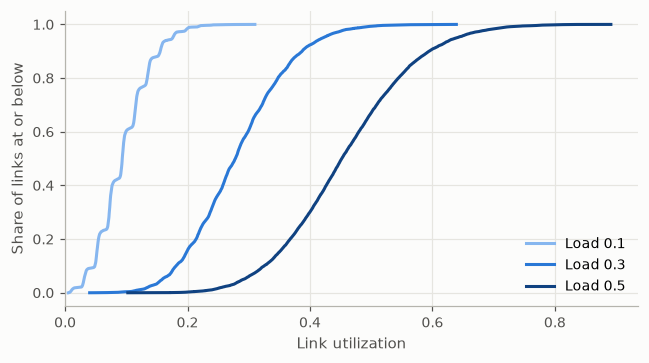

In [11]:
for title, rows in common.panels(links):
    figure, axis = plt.subplots(figsize=(6, 3.4))
    for value, group in rows.groupby(common.SETTING):
        utilization = np.sort(group["utilization"].to_numpy())
        axis.plot(utilization, np.linspace(0, 1, len(utilization)), color=colors[value], label=common.setting_name(value))
    axis.set(xlabel="Link utilization", ylabel="Share of links at or below", xlim=(0, None), title=title)
    axis.legend()
    figure.tight_layout()

## Fan-in

Spraypoint should bring a destination's traffic in through many neighbors. `busiest_share` is the share of its traffic arriving from its busiest neighbor, and `neighbors` is how many deliver anything.

In [12]:
display(common.fan_in_table(links, common.SETTINGS))

,busiest_share,neighbors
load,,
0.10,0.18,16.00
0.30,0.13,16.00
0.50,0.12,16.00
